![Ironhack logo](https://user-images.githubusercontent.com/23629340/40541063-a07a0a8a-601a-11e8-91b5-2f13e4e6b441.png)

# Gradient Descent: How Models Learn
*Data Science & Machine Learning - Week 5, Day 4*

## How to use this notebook

This notebook opens up the step that every model in the course relies on: **learning**, that is, finding the parameters that make a model fit the data. The method behind almost all of them, from linear regression to deep neural networks, is **gradient descent**.

You will learn:

+ What a derivative tells us, and how to follow it downhill to the minimum of a function.
+ Why the step size matters, and what happens when it is too small or too large.
+ How learning from data becomes minimising a loss function, and which loss functions are common.
+ Batch, stochastic and mini-batch gradient descent, and how automatic differentiation computes gradients for us.

The slides **3. Gradient Descent** in this folder go with this notebook, and the neural network notebook (`1. Deep Learning 0`) builds on it.

Run the cells in order, from top to bottom. Everything is plain NumPy: no data to download, and the whole notebook runs in a few seconds.

## Table of contents

- [Setup](#Setup)
- [0. Before we start](#0.-Before-we-start)
- [1. Gradient descent](#1.-Gradient-descent)
    - [First approach: the numerical derivative](#First-approach:-the-numerical-derivative)
    - [Second approach: the exact derivative](#Second-approach:-the-exact-derivative)
    - [The step size](#The-step-size)
- [2. From derivatives to gradients](#2.-From-derivatives-to-gradients)
- [3. How to learn from data](#3.-How-to-learn-from-data)
    - [3.1 Square loss](#3.1-Square-loss)
    - [3.2 Hinge loss](#3.2-Hinge-loss)
    - [3.3 Logistic loss](#3.3-Logistic-loss)
    - [3.4 Cross-entropy loss](#3.4-Cross-entropy-loss)
- [4. Batch gradient descent](#4.-Batch-gradient-descent)
    - [4.1 Stochastic gradient descent](#4.1-Stochastic-gradient-descent)
    - [4.2 Mini-batch gradient descent](#4.2-Mini-batch-gradient-descent)
- [5. Extra: automatic differentiation](#5.-Extra:-automatic-differentiation)
    - [Forward mode](#Forward-mode)
    - [Reverse mode](#Reverse-mode)

## Setup

The next cell installs the libraries this notebook needs. Run it once: `%pip` installs them into the same environment the notebook is running in.

In [1]:
%pip install -q numpy matplotlib

You should consider upgrading via the '/private/tmp/s507/bin/python -m pip install --upgrade pip' command.


Note: you may need to restart the kernel to use updated packages.


If pip upgraded a library you had already imported, restart the kernel (**Kernel > Restart**) before going on. Otherwise carry on: the next cell imports everything the notebook uses.

In [2]:
import random

import numpy as np
import matplotlib.pyplot as plt

random.seed(0)
np.random.seed(0)

Gradient descent starts from a random point, so the seeds make the results repeatable: every run of the notebook starts from the same "random" values.

## 0. Before we start

The simplest thing we can try to minimise a function $f(x)$ is to sample two points relatively near each other, and repeatedly take a step away from the larger value. This simple algorithm has a severe limitation: it can't get closer to the true minimum than the step size.

The **Nelder-Mead** method adjusts the step size dynamically, based on the loss of the new point. If the new point is better than any previously seen value, it expands the step size to accelerate towards the bottom. If the new point is worse, it contracts the step size to converge around the minimum. The usual settings are to halve the step size when contracting and double it when expanding.

This method extends easily to more dimensions: all it needs is one more point than there are dimensions. The simplest approach is then to replace the worst point with a point reflected through the centroid of the remaining $n$ points. If this point is better than the best current point, we can try stretching out exponentially along this line. If the new point isn't much better than the previous value, we are stepping across a valley, so we shrink the step towards a better point.

> See ["An Interactive Tutorial on Numerical Optimization"](http://www.benfrederickson.com/numerical-optimization/)

Questions:

+ What are the limitations of this method from a computational point of view?
+ In which cases is it a real alternative?

**Gradient-based** optimisation methods provide an alternative to sampling approaches.

## 1. Gradient descent

Suppose we have a function $f(w): \mathbf{R} \rightarrow \mathbf{R}$, and our objective is to find the argument $w$ that minimises it (to maximise, minimise $-f(w)$ instead). The key concept is the **derivative**.

The derivative of $f$ with respect to $w$, written $f'(w)$ or $\frac{df}{dw}$, measures the rate at which the value of the function changes when $w$ changes. It is defined as the limit:

$$ f'(w) = \lim_{h \rightarrow 0} \frac{f(w + h) - f(w)}{h} $$

The derivative says how a small change in the input scales into a change in the output. Knowing $f(w)$ and $f'(w)$ at a point $w$, we can predict the value of the function at a nearby point:

$$ f(w + h) \approx f(w) + h f'(w) $$

### First approach: the numerical derivative

Following these steps decreases the value of the function:

+ Start from a random value $w^0$.
+ Compute the derivative $f'(w) = \lim_{h \rightarrow 0} \frac{f(w + h) - f(w)}{h}$.
+ Walk small steps in the opposite direction of the derivative, $w^{i+1} = w^i - h f'(w^i)$, because we know that $f(w - h f'(w))$ is less than $f(w)$ for small enough $h$, until $f'(w) \approx 0$.

The search ends when the derivative is zero, because then we have no more information about which direction to move in. A point $w$ where $f'(w) = 0$ is called a **critical** or **stationary** point of $f$.

All extrema (maxima and minima) are critical points, because $f(w)$ is lower or higher there than at all neighbouring points. But they are not the only critical points: a third kind is the **saddle point**, where the derivatives are zero but the function has neither a maximum nor a minimum.

If $f$ is a **convex** function, a point where the derivative is zero is its minimum. Otherwise it could be a local minimum, a local maximum or a saddle point.

We don't always have a formula for the derivative, but we can always **estimate** it: move $x$ by a tiny amount $h$ and measure how much $f$ changes. That is the definition above, with a small $h$ instead of the limit. The cell below does it for $f(x) = x^2$ at $x = 2$, with $h = 0.00001$.

In [3]:
def f(x):
    return x**2

def fin_dif(x, f, h=0.00001):
    '''Derivative of f at x, estimated by the finite difference method.'''
    return (f(x + h) - f(x)) / h

x = 2.0
print("numerical derivative at x = 2: {:.4f}".format(fin_dif(x, f)))
print("exact derivative 2x at x = 2:  {:.4f}".format(2 * x))

numerical derivative at x = 2: 4.0000
exact derivative 2x at x = 2:  4.0000


The estimate matches the exact derivative of $x^2$, which is $2x = 4$ at $x = 2$. It is not perfect: printed with more decimals it is $4.00001$, off by exactly $h$.

> **Note:** the *centered difference* formula is more accurate for numerical derivatives:
>
> $$ \lim_{h \rightarrow 0} \frac{f(x + h) - f(x - h)}{2h} $$
>
> By Taylor's theorem, the error of the forward difference above is $O(h)$, while the error of the centered difference is $O(h^2)$.

Numerical derivatives have two problems:

+ They are approximate.
+ They are slow: every derivative needs two evaluations of the function, $f(x + h)$ and $f(x - h)$, and a model with many parameters needs one derivative per parameter.

Our knowledge of calculus can help!

### Second approach: the exact derivative

When we know a formula for the derivative of the function we want to minimise, we can use it directly. Start at a random point and move in the direction of steepest descent:

+ Start from a random value of $x$.
+ Compute the derivative $f'(x)$ from its formula.
+ Walk a small step in the opposite direction of the derivative.

Take $f(x) = x^2 - 6x + 5$, whose derivative is $f'(x) = 2x - 6$. The minimum is where $f'(x) = 0$, at $x = 3$.

Let's start at $x = 15$ and take one step against the derivative, using the derivative itself as the length of the step: $f'(15) = 24$, so we move to $15 - 24 = -9$.

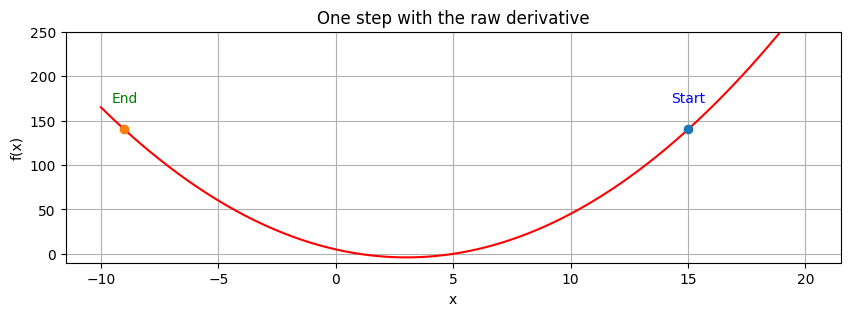

In [4]:
def f(x):
    return x**2 - 6*x + 5

def f_derivative(x):
    return 2*x - 6

xs = np.linspace(-10, 20, 100)
start = 15
end = start - f_derivative(start)

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(xs, f(xs), "r-")
ax.plot([start], [f(start)], "o")
ax.plot([end], [f(end)], "o")
ax.text(start, f(start) + 30, "Start", ha="center", color="blue")
ax.text(end, f(end) + 30, "End", ha="center", color="green")
ax.set_ylim(-10, 250)
ax.set_xlabel("x")
ax.set_ylabel("f(x)")
ax.set_title("One step with the raw derivative")
ax.grid(True)
plt.show()

**There is a problem! Which one?**

We jumped right over the minimum at $x = 3$ and landed at $x = -9$, where $f$ is exactly as high as where we started: $f(15) = f(-9) = 140$. The derivative gives the right **direction**, but its size is not a good **distance**: far from the minimum it is large, and we overshoot. We need a **step size** to scale it down.

Now we scale each step by a step size of 0.1. Each iteration of the loop:

1. Computes the derivative at the current point.
2. Multiplies it by the step size to get the move.
3. Moves against the derivative: `current_x = old_x - step_size * gradient`.
4. Records the new point and its value $f(x)$, for the plots below.

The loop stops when a step moves $x$ by less than `precision`, that is, when we have stopped making progress.

In [5]:
step_size = 0.1
precision = 0.0001

old_x = 0
current_x = start
path = []
costs = []

while abs(current_x - old_x) > precision:
    old_x = current_x
    gradient = f_derivative(old_x)
    current_x = old_x - step_size * gradient
    path.append(current_x)
    costs.append(f(current_x))
    print("step {:2d}: x = {:.4f}".format(len(path), current_x))

print("Local minimum occurs at x = {:.2f}, after {} steps".format(current_x, len(path)))

step  1: x = 12.6000
step  2: x = 10.6800
step  3: x = 9.1440
step  4: x = 7.9152
step  5: x = 6.9322
step  6: x = 6.1457
step  7: x = 5.5166
step  8: x = 5.0133
step  9: x = 4.6106
step 10: x = 4.2885
step 11: x = 4.0308
step 12: x = 3.8246
step 13: x = 3.6597
step 14: x = 3.5278
step 15: x = 3.4222
step 16: x = 3.3378
step 17: x = 3.2702
step 18: x = 3.2162
step 19: x = 3.1729
step 20: x = 3.1384
step 21: x = 3.1107
step 22: x = 3.0885
step 23: x = 3.0708
step 24: x = 3.0567
step 25: x = 3.0453
step 26: x = 3.0363
step 27: x = 3.0290
step 28: x = 3.0232
step 29: x = 3.0186
step 30: x = 3.0149
step 31: x = 3.0119
step 32: x = 3.0095
step 33: x = 3.0076
step 34: x = 3.0061
step 35: x = 3.0049
step 36: x = 3.0039
step 37: x = 3.0031
step 38: x = 3.0025
step 39: x = 3.0020
step 40: x = 3.0016
step 41: x = 3.0013
step 42: x = 3.0010
step 43: x = 3.0008
step 44: x = 3.0007
step 45: x = 3.0005
step 46: x = 3.0004
step 47: x = 3.0003
Local minimum occurs at x = 3.00, after 47 steps


The first step moves $x$ from 15 to 12.6, a move of 2.4. Later moves get smaller and smaller, even though the step size stays at 0.1: the derivative shrinks as we approach the minimum, so the moves shrink with it. After @@STEPS@@ steps a move is smaller than `precision`, and the loop stops at $x \approx 3$, the true minimum.

Two views of the same run: the value of $f$ after each step, and the points on the curve.

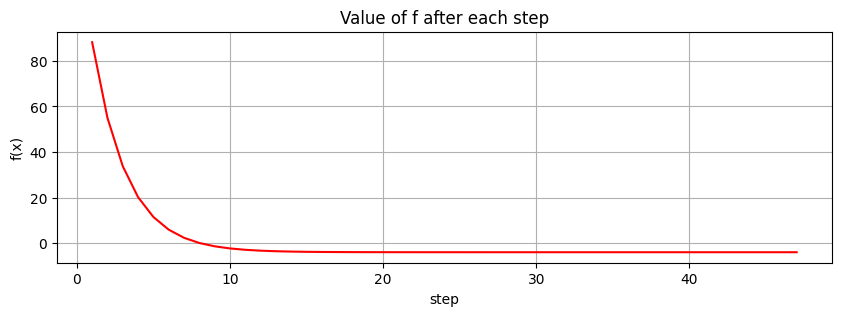

In [6]:
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(range(1, len(costs) + 1), costs, "r-")
ax.set_xlabel("step")
ax.set_ylabel("f(x)")
ax.set_title("Value of f after each step")
ax.grid(True)
plt.show()

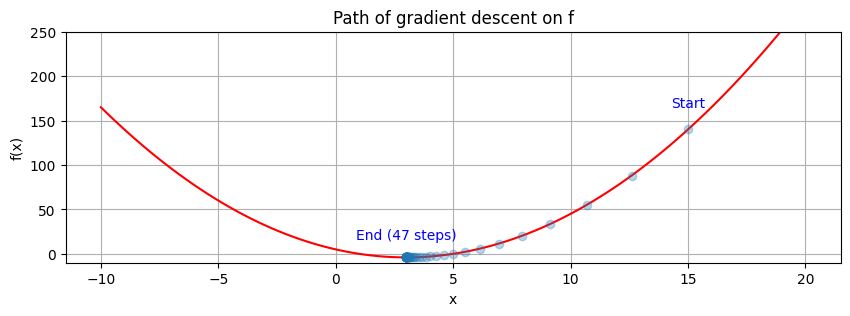

In [7]:
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(xs, f(xs), "r-")
ax.plot([start] + path, [f(start)] + costs, "o", alpha=0.3)
ax.text(start, f(start) + 25, "Start", ha="center", color="blue")
ax.text(path[-1], costs[-1] + 20, "End ({} steps)".format(len(path)), ha="center", color="blue")
ax.set_ylim(-10, 250)
ax.set_xlabel("x")
ax.set_ylabel("f(x)")
ax.set_title("Path of gradient descent on f")
ax.grid(True)
plt.show()

Most of the progress happens in the first 10 steps; after that the points pile up around the minimum, where $f(3) = -4$. Fast at first and slower near the minimum: that pattern is typical of gradient descent.

### The step size

The step size, often called **alpha** ($\alpha$) or the **learning rate**, is a slippery concept: if it is too small, we converge to the solution slowly; if it is too large, we can move away from the solution.

There are several policies for choosing it:

+ Constant step size. The step size then determines the precision of the solution.
+ Decreasing step sizes.
+ At each step, select the optimal step.

The last policy is good, but too expensive.

> **Try it:** set `step_size` in the loop above to 0.01, and re-run the loop and both plots. Then try 0.5 and 0.9. Which one needs the fewest steps, and which one zig-zags around the minimum? Keep it below 1.0: at exactly 1.0 the descent bounces between 15 and -9 forever, and above 1.0 each step overshoots further than the last until the numbers overflow.

## 2. From derivatives to gradients

Now consider an $n$-dimensional function $f: \mathbf{R}^n \rightarrow \mathbf{R}$. For example:

$$ f(\mathbf{x}) = \sum_{i=1}^n x_i^2 $$

Our objective is to find the argument $\mathbf{x}$ that minimises this function.

The **gradient** of $f$ is the vector whose components are the $n$ partial derivatives of $f$, one per variable. It is a vector-valued function:

$$ \nabla f = \Big(\frac{\partial f}{\partial x_1}, \dots, \frac{\partial f}{\partial x_n}\Big) $$

The gradient points in the direction in which the function increases fastest, so its opposite points downhill.

We can estimate each partial derivative the same way as before: move one coordinate by $h$, keep the others fixed, and measure the change in $f$. This time we use the more accurate centered difference. Stacking the $n$ partial derivatives gives the gradient.

In [8]:
def f(x):
    return sum(x_i**2 for x_i in x)

def fin_dif_partial_centered(x, f, i, h=1e-6):
    '''Partial derivative of f at x with respect to the i-th component, by centered difference.'''
    w1 = [x_j + (h if j == i else 0) for j, x_j in enumerate(x)]
    w2 = [x_j - (h if j == i else 0) for j, x_j in enumerate(x)]
    return (f(w1) - f(w2)) / (2 * h)

def gradient_centered(x, f, h=1e-6):
    '''Gradient vector of f at x, by centered difference.'''
    return [round(fin_dif_partial_centered(x, f, i, h), 10) for i, _ in enumerate(x)]

x = [1.0, 1.0, 1.0]
print("f(x) =", "{:.6f}".format(f(x)))
print("gradient =", gradient_centered(x, f))

f(x) = 3.000000
gradient = [2.0000000001, 2.0000000001, 2.0000000001]


At $(1, 1, 1)$ the function $f(\mathbf{x}) = x_1^2 + x_2^2 + x_3^2$ is 3, and the estimated gradient is $(2, 2, 2)$, up to rounding. That matches the exact gradient: each partial derivative is $2x_i$, so $\nabla f = 2\mathbf{x}$.

With the gradient, the steps to minimise the function are the same as in one dimension:

+ Start from a random vector $\mathbf{x}$.
+ Compute the gradient vector.
+ Walk a small step in the opposite direction of the gradient.

> This way of computing the gradient is very expensive: if $\mathbf{x}$ has dimension $n$, we have to evaluate $f$ at $2n$ points.

## 3. How to learn from data

**Learning from data** is concerned with designing algorithms that let computers infer, from data, a model that gives either a compact representation of the raw data or good predictions on new data. The former is **unsupervised** learning, the latter **supervised** learning.

Let's look at the supervised learning problem from an optimisation point of view. Learning a model from data usually involves these elements:

+ A dataset $(\mathbf{x}, y)$ of $n$ examples. For example, $(\mathbf{x}, y)$ can represent:

  + $\mathbf{x}$: the behaviour of a game player; $y$: monthly payments.
  + $\mathbf{x}$: sensor data about your car engine; $y$: probability of engine failure.
  + $\mathbf{x}$: financial data of a bank customer; $y$: customer rating.

  If $y$ is a real value, the problem is called **regression**. If $y$ is binary or categorical, it is called **classification**.

+ A model $M$, described by a set of parameters $\mathbf{w}$.

+ A target function $f_{(\mathbf{x}, y)}(\mathbf{w})$ that we want to minimise, measuring the discrepancy between our data and the model.

+ The gradient of the target function, $\nabla f_{(\mathbf{x}, y)}(\mathbf{w})$, with respect to the model parameters.

In regression, $f_{(\mathbf{x}, y)}(\mathbf{w})$ measures the errors of the model $M$. Fitting the model means finding the parameters $\mathbf{w}$ that minimise:

$$ f_{(\mathbf{x}, y)}(\mathbf{w}) = \frac{1}{n} \sum_{i} (y_i - M(\mathbf{x}_i, \mathbf{w}))^2 $$

Other regression and classification problems use other ways of measuring the errors of the model. These formulations are known as the **loss function** of the problem. In the classification losses below, the labels are $y_i \in \{-1, 1\}$ and $f(\mathbf{x}_i)$ is the model's score for example $i$.

### 3.1 Square loss

Also called the Euclidean loss. In regression problems, the most common loss function is the square loss:

$$ L(y, f(\mathbf{x})) = \frac{1}{n} \sum_i (y_i - f(\mathbf{x}_i))^2 $$

The square loss can also be rewritten for classification:

$$ L(y, f(\mathbf{x})) = \frac{1}{n} \sum_i (1 - y_i f(\mathbf{x}_i))^2 $$

### 3.2 Hinge loss

Also called the margin loss; it is the loss behind **support vector machines**. It is defined as:

$$ L(y, f(\mathbf{x})) = \frac{1}{n} \sum_i \max(0, 1 - y_i f(\mathbf{x}_i)) $$

The hinge loss is a relatively tight, convex upper bound on the 0-1 loss (the share of misclassified examples).

### 3.3 Logistic loss

The loss behind **logistic regression**. It converges at a similar rate to the hinge loss, and since it is smooth, simple gradient descent methods can be used:

$$ L(y, f(\mathbf{x})) = \frac{1}{n} \sum_i \log(1 + \exp(-y_i f(\mathbf{x}_i))) $$

### 3.4 Cross-entropy loss

Cross-entropy, used with a **softmax** classifier, is the standard loss for **multiclass problems**. We focus on models that assume the classes are mutually exclusive.

Here the labels have the form $\mathbf{y}_i = (1.0, 0.0, 0.0)$. If our model predicts a different distribution, say $f(\mathbf{x}_i) = (0.4, 0.1, 0.5)$, we would like to nudge the parameters so that $f(\mathbf{x}_i)$ gets closer to $\mathbf{y}_i$.

Claude Shannon showed that if you want to send a series of messages composed of symbols from an alphabet with distribution $y$ ($y_j$ is the probability of the $j$-th symbol), then to use the smallest number of bits on average, you should assign $\log(\frac{1}{y_j})$ bits to the $j$-th symbol.

The optimal number of bits is known as **entropy**:

$$ H(\mathbf{y}) = \sum_j y_j \log\frac{1}{y_j} = - \sum_j y_j \log y_j $$

**Cross-entropy** is the number of bits we need if we encode the symbols using a wrong distribution $\hat y$:

$$ H(y, \hat y) = - \sum_j y_j \log \hat y_j $$

In our case, the real distribution is $\mathbf{y}$ and the "wrong" one is $f(\mathbf{x}_i)$. So minimising the cross-entropy with respect to the model parameters gives the model that best approximates our labels, seen as a probability distribution.

To classify $\mathbf{x}_i$ we could take the index of the largest value of $f(\mathbf{x}_i)$, but **softmax** gives a more intuitive output, normalised class probabilities, with a probabilistic interpretation:

$$ P(\mathbf{y}_i = j \mid \mathbf{x}_i) = \frac{e^{f_j(\mathbf{x}_i)}}{\sum_k e^{f_k(\mathbf{x}_i)}} $$

where $f_k$ is a linear classifier for class $k$. The loss for example $i$ is the negative log of the probability given to its true class.

## 4. Batch gradient descent

Now let's put the pieces together on data. The data comes from the line $y = 2x$, for $x = 0, 1, \dots, 9$, and the model is $y = wx$, with a single parameter $w$. Learning means finding $w$, and we know the answer should be 2.

+ **Target function:** the mean squared error, $f(w) = \frac{1}{n} \sum_i (y_i - w x_i)^2$.
+ **Gradient:** its derivative with respect to $w$, $f'(w) = \frac{1}{n} \sum_i (2 w x_i^2 - 2 x_i y_i)$.
+ **Step:** $w \leftarrow w - \alpha f'(w)$.

This version is called **batch** gradient descent because every step uses the whole dataset, the whole "batch", to compute the gradient.

In [9]:
x = np.arange(10)
y = 2 * x

def target_f(x, y, w):
    return np.sum((y - x * w)**2) / x.size

def gradient_f(x, y, w):
    return np.sum(2 * w * x**2 - 2 * x * y) / x.size

def step(w, grad, alpha):
    return w - alpha * grad

`BGD` starts from a random $w$ between 0 and 1, and takes steps of size `alpha` until the loss changes by less than `toler` from one step to the next.

In [10]:
def BGD(target_f, gradient_f, x, y, toler=1e-6, alpha=0.01):
    '''Batch gradient descent with a fixed step size.'''
    w = random.random()
    val = target_f(x, y, w)
    while True:
        gradient = gradient_f(x, y, w)
        next_w = step(w, gradient, alpha)
        next_val = target_f(x, y, next_w)
        if abs(val - next_val) < toler:
            return w
        w, val = next_w, next_val

print("w = {:.6f}".format(BGD(target_f, gradient_f, x, y)))

w = 1.999893


Batch gradient descent finds $w$ = @@BGD_W@@, very close to the true value 2. It is not exactly 2 because the loop stops as soon as one step improves the loss by less than `toler`.

### 4.1 Stochastic gradient descent

The function above evaluates the whole dataset $(\mathbf{x}_i, y_i)$ at every step. If the dataset is large, this is too costly. Instead, we use **stochastic gradient descent** (SGD).

When learning from data, the cost function is additive: it is a sum of the errors on each example. So we can **estimate** the gradient, and move towards the minimum, using only **one data sample** (or a small sample), and find the minimum by repeating this estimate over the dataset.

A full pass over the dataset is called an **epoch**. During an epoch, the data must be visited in a random order.

This method comes with some theoretical guarantees of finding a good minimum:

+ SGD uses an inaccurate gradient at each iteration, and there is no free lunch: the cost of the approximate gradient is that it converges more slowly than gradient descent, measured in iterations.
+ The convergence of SGD has been analysed with the theories of convex minimisation and stochastic approximation: it converges almost surely to a global minimum when the objective function is convex or pseudoconvex, and otherwise almost surely to a local minimum.

The same data as before, as pairs $(x_i, y_i)$ that SGD will visit one at a time:

In [11]:
data = list(zip(x, y))

for x_i, y_i in data:
    print("{:3d} {:3d}".format(x_i, y_i))

  0   0
  1   2
  2   4
  3   6
  4   8
  5  10
  6  12
  7  14
  8  16
  9  18


Two functions:

+ `in_random_order` yields the data points in a shuffled order, so each epoch visits them differently.
+ `SGD` runs up to `epochs` passes over the data. In each pass it updates $w$ once per data point, using the gradient of that single point. Before each pass it checks the loss on the whole dataset: if it improved, it remembers that $w$ and resets the step size; if not, it shrinks the step size to 95% of its value. It returns the best $w$ it has seen.

In [12]:
def in_random_order(data):
    '''Yield the data points in a random order.'''
    indexes = list(range(len(data)))
    random.shuffle(indexes)
    for i in indexes:
        yield data[i]

def SGD(target_f, gradient_f, x, y, toler=1e-6, epochs=100, alpha_0=0.01):
    '''
    Stochastic gradient descent. The step size shrinks to 95% after every
    epoch without improvement, and resets when the loss improves again.
    '''
    data = list(zip(x, y))
    w = random.random()
    alpha = alpha_0
    min_w, min_val = float("inf"), float("inf")
    epoch = 0
    iteration_no_increase = 0
    while epoch < epochs and iteration_no_increase < 100:
        val = target_f(x, y, w)
        if min_val - val > toler:
            min_w, min_val = w, val
            alpha = alpha_0
            iteration_no_increase = 0
        else:
            iteration_no_increase += 1
            alpha *= 0.95
        for x_i, y_i in in_random_order(data):
            gradient_i = gradient_f(x_i, y_i, w)
            w = w - alpha * gradient_i
        epoch += 1
    return min_w

print("w = {:.6f}".format(SGD(target_f, gradient_f, x, y)))

w = 2.000000


SGD finds $w$ = @@SGD_W@@. Each update used a single data point, so each step was noisier than in batch gradient descent, but SGD made 10 updates per pass over the data instead of one. On large datasets, that trade is what makes training possible.

### 4.2 Mini-batch gradient descent

In code, batch gradient descent looks something like this:

```python
nb_epochs = 100
for i in range(nb_epochs):
    grad = evaluate_gradient(target_f, data, w)
    w = w - learning_rate * grad
```

For a set number of epochs, we compute the gradient of the target function over the whole dataset, with respect to the parameter vector, and take one step.

**Stochastic gradient descent** instead updates the parameters for each training example and label:

```python
nb_epochs = 100
for i in range(nb_epochs):
    np.random.shuffle(data)
    for sample in data:
        grad = evaluate_gradient(target_f, sample, w)
        w = w - learning_rate * grad
```

**Mini-batch gradient descent** takes the best of both worlds, and updates the parameters once for every mini-batch of $n$ training examples:

```python
nb_epochs = 100
for i in range(nb_epochs):
    np.random.shuffle(data)
    for batch in get_batches(data, batch_size=50):
        grad = evaluate_gradient(target_f, batch, w)
        w = w - learning_rate * grad
```

Mini-batch SGD works with a less noisy estimate of the gradient than plain SGD. However, as the mini-batch grows, the number of updates per computation goes down, and eventually it becomes as inefficient as batch gradient descent.

The best trade-off, in terms of computational efficiency, depends on the data distribution, the kind of model, and how the computations are implemented. This is what Keras does: `batch_size=64` in `model.fit` means mini-batches of 64 examples.

## 5. Extra: automatic differentiation

> The **backpropagation** algorithm was originally introduced in the 1970s, but its importance wasn't fully appreciated until a famous 1986 paper by David Rumelhart, Geoffrey Hinton, and Ronald Williams. (Michael Nielsen in "Neural Networks and Deep Learning", http://neuralnetworksanddeeplearning.com/chap2.html).

> **Backpropagation** is the key algorithm that makes training deep models computationally tractable. For modern neural networks, it can make training with gradient descent as much as ten million times faster, relative to a naive implementation. That's the difference between a model taking a week to train and taking 200,000 years. (Christopher Olah, 2016)

To optimise our models, we need the derivative of the loss function with respect to every model parameter. There are four main ways to compute derivatives in a program:

+ working out the derivatives by hand and coding the result (as in the original paper describing backpropagation);
+ numerical differentiation, using finite difference approximations;
+ symbolic differentiation, using expression manipulation in software such as SymPy;
+ and **automatic differentiation** (AD).

**Automatic differentiation** works by systematically applying the **chain rule** of calculus at the level of elementary operations.

Let $y = f(g(x))$ be our target function. In its basic form, the chain rule states:

$$ \frac{\partial y}{\partial x} = \frac{\partial y}{\partial g} \frac{\partial g}{\partial x} $$

If there is more than one variable $g_i$ between $y$ and $x$ (for example, if $f$ is a two-dimensional function such as $f(g_1(x), g_2(x))$), then:

$$ \frac{\partial y}{\partial x} = \sum_i \frac{\partial y}{\partial g_i} \frac{\partial g_i}{\partial x} $$

AD relies on the fact that every numerical computation is ultimately a composition of a finite set of elementary operations whose derivatives are known. That lets it evaluate derivatives accurately, at machine precision, with only a small constant overhead.

For example, take this function, which represents a 1-layer neural network model:

$$ f(x) = \frac{1}{1 + e^{- (w x + b)}} $$

First, we write how to evaluate $f(x)$ as a sequence of primitive operations:

```python
x = ?
f1 = w * x
f2 = f1 + b
f3 = -f2
f4 = 2.718281828459 ** f3
f5 = 1.0 + f4
f = 1.0/f5
```

The question mark indicates that $x$ is a value that must be provided. This *program* computes the value of $f$, and on the way **fills in the intermediate variables** `f1` to `f5`.

### Forward mode

We can evaluate $\frac{\partial f}{\partial x}$ at some $x$ with the chain rule, going forward through the program. This is called **forward-mode differentiation**.

`dfdx_forward` runs the program line by line, and next to each intermediate value `f1` to `f5` it carries `p1` to `p5`: the derivative of that value with respect to $x$, obtained from the previous one with the chain rule. We then compare the result with the finite difference from section 1.

In [13]:
def f(x, w, b):
    f1 = w * x
    f2 = f1 + b
    f3 = -f2
    f4 = 2.718281828459 ** f3
    f5 = 1.0 + f4
    return 1.0 / f5

def dfdx_forward(x, w, b):
    f1 = w * x
    p1 = w                            # p1 = df1/dx
    f2 = f1 + b
    p2 = p1 * 1.0                     # p2 = p1 * df2/df1
    f3 = -f2
    p3 = p2 * -1.0                    # p3 = p2 * df3/df2
    f4 = 2.718281828459 ** f3
    p4 = p3 * 2.718281828459 ** f3    # p4 = p3 * df4/df3
    f5 = 1.0 + f4
    p5 = p4 * 1.0                     # p5 = p4 * df5/df4
    f = 1.0 / f5
    df = p5 * -1.0 / f5 ** 2.0        # df/dx = p5 * df/df5
    return f, df

der = (f(3 + 0.00001, 2, 1) - f(3, 2, 1)) / 0.00001

print("Value of the function at (3, 2, 1):        ", f(3, 2, 1))
print("df/dx derivative (fin diff) at (3, 2, 1):  ", der)
print("df/dx derivative (forward AD) at (3, 2, 1):", dfdx_forward(3, 2, 1)[1])

Value of the function at (3, 2, 1):         0.9990889488055992
df/dx derivative (fin diff) at (3, 2, 1):   0.0018204242002717306
df/dx derivative (forward AD) at (3, 2, 1): 0.0018204423602438651


The two derivatives agree to about 7 significant digits. The difference is the error of the finite difference: the forward-mode value is exact, up to machine precision.

Note that this *program* can be derived automatically, as long as we have **subroutines implementing the derivatives of the primitive functions** (such as $\exp{(x)}$ or $1/x$) and all the intermediate variables are computed in the right order.

### Reverse mode

Forward differentiation is efficient for functions $f : \mathbb{R}^n \rightarrow \mathbb{R}^m$ with $n \ll m$: it needs only $O(n)$ sweeps, one per input.

For $n \gg m$ we need a different technique. We rewrite the chain rule as:

$$ \frac{\partial f}{\partial x} = \frac{\partial g}{\partial x} \frac{\partial f}{\partial g} $$

to propagate derivatives backward from a given output. This is called **reverse-mode differentiation**. The reverse pass starts at the end, with $\frac{\partial f}{\partial f} = 1$, and propagates backward to all the dependencies.

`dfdx_backward` first runs the program forward to get every intermediate value. Then it walks back from the output: `pf` is $\frac{\partial f}{\partial f} = 1$, and each line multiplies in the derivative of one more step, until it reaches $x$.

In [14]:
def dfdx_backward(x, w, b):
    f1 = w * x
    f2 = f1 + b
    f3 = -f2
    f4 = 2.718281828459 ** f3
    f5 = 1.0 + f4
    f = 1.0 / f5

    pf = 1.0                           # pf = df/df
    p5 = 1.0 * -1.0 / (f5 * f5) * pf   # p5 = pf * df/df5
    p4 = p5 * 1.0                      # p4 = p5 * df5/df4
    p3 = p4 * np.log(2.718281828459) \
          * 2.718281828459 ** f3       # p3 = p4 * df4/df3
    p2 = p3 * -1.0                     # p2 = p3 * df3/df2
    p1 = p2 * 1.0                      # p1 = p2 * df2/df1
    dfx = p1 * w                       # dfx = p1 * df1/dx
    return f, dfx

print("df/dx derivative (reverse AD) at (3, 2, 1):", dfdx_backward(3, 2, 1)[1])

df/dx derivative (reverse AD) at (3, 2, 1): 0.0018204423602438348


Reverse mode gives the same derivative as forward mode, down to the last few digits.

Why do neural networks use reverse mode? A network has a single output we care about, the loss, and thousands or millions of inputs: the weights. Forward mode would need one pass per weight; reverse mode gets the derivative with respect to every weight in **one backward pass**. Reverse-mode differentiation applied to a neural network is exactly **backpropagation**.

Any complex function that can be decomposed into elementary functions can be differentiated automatically, at machine precision, by this algorithm. **We no longer need to code complex derivatives to apply SGD!** Libraries like TensorFlow and PyTorch do it for us.